# TP 4 Machine Learning
### By Laouari Basmala

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


# 2. DATASET

df = pd.read_csv("dataset_spam_tp4.csv") 

print("First 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical description:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

df.groupby('type_mail')[['loterie','heritage','seminaire','soutenance']].apply(
lambda g: (g > 0).sum())
print("Shape:", df.shape)

First 5 rows:
   id_mail  nb_liens expediteur_connu  gratuit  offre  urgent  gagner  \
0        1         0              Non        0      0       0       0   
1        2         0              Oui        0      0       0       0   
2        3         0              Non        1      0       0       0   
3        4         0              Non        0      1       0       0   
4        5         3              Non        0      1       0       1   

   cliquer  facture  reunion  projet  rapport  cordialement  loterie  \
0        0        1        0       1        1             2        0   
1        0        1        0       0        0             1        0   
2        0        0        1       0        1             1        0   
3        0        0        0       0        1             1        0   
4        1        0        0       0        1             0        0   

   heritage  seminaire  soutenance type_mail  
0         0          0           0  Legitime  
1         0         

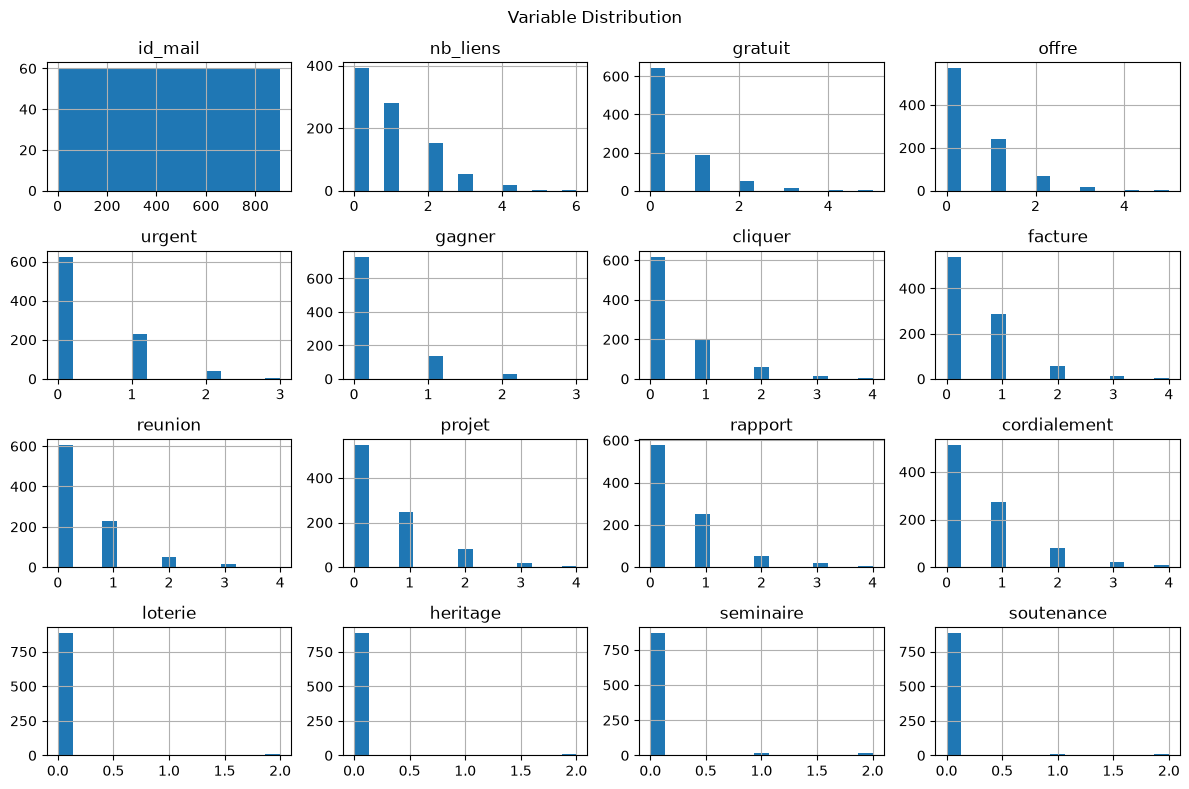

In [2]:
df.hist(figsize=(12, 8), bins=15)

plt.suptitle("Variable Distribution")
plt.tight_layout()
plt.show()

In [3]:
df['expediteur_connu'] = df['expediteur_connu'].map({
    'Oui': 1,
    'Non': 0
})

print(df['expediteur_connu'].value_counts(dropna=False))
print(df['type_mail'].value_counts())

expediteur_connu
1    483
0    417
Name: count, dtype: int64
type_mail
Legitime    577
Spam        323
Name: count, dtype: int64


A.2 – Variable types

Quantitative (discrete): nb_liens and the 14 word-count variables (gratuit, offre, ..., soutenance). All are non-negative integers.
Qualitative: expediteur_connu (binary Yes/No) and type_mail (the target, 2 classes).
id_mail is just an identifier with no predictive value, so it's excluded.

Count variables suit a multinomial model because it models exactly the number of occurrences of each word in a message.

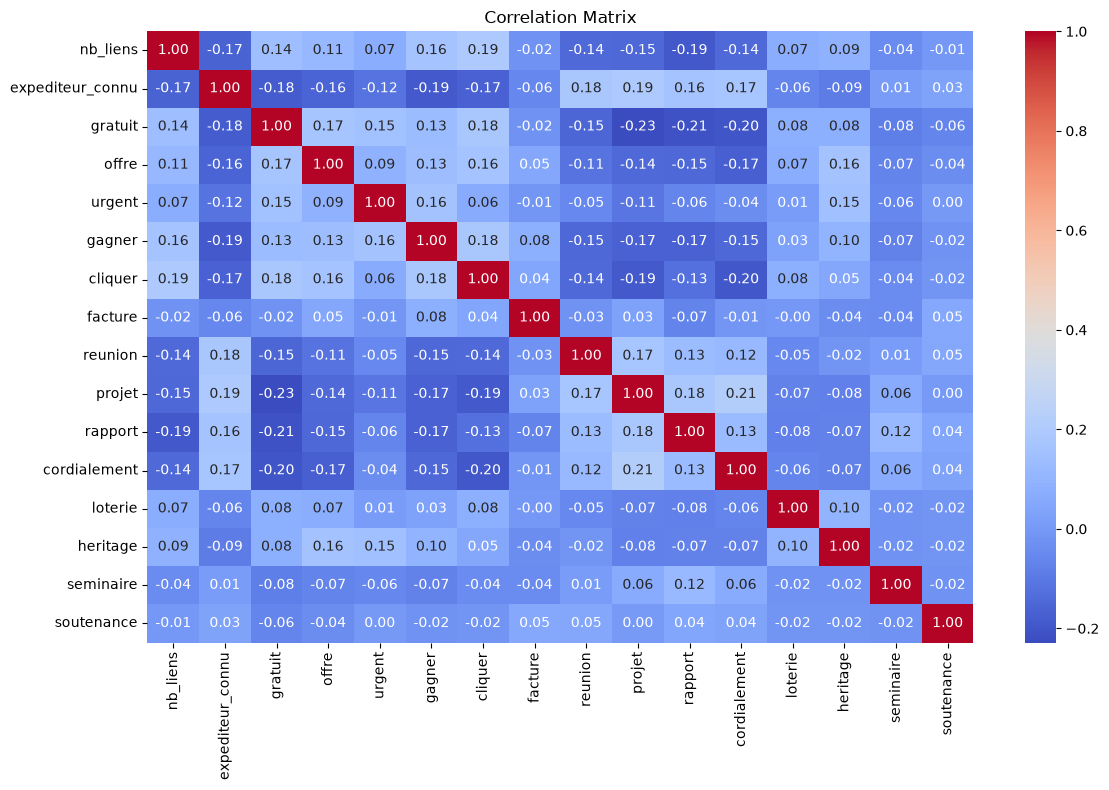

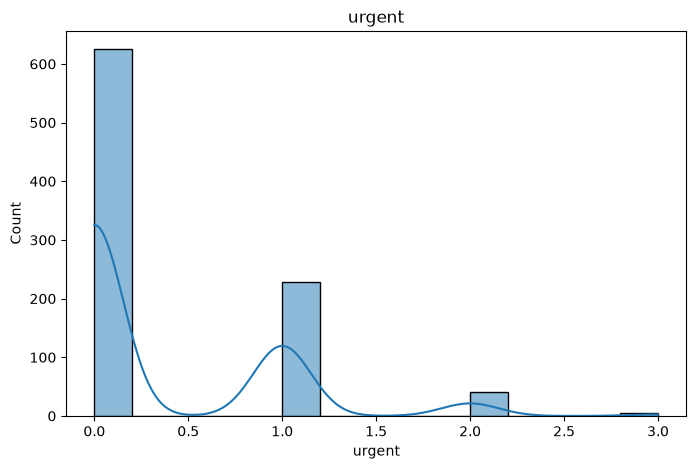

In [4]:

# Correlation matrix 
numeric_cols = df.select_dtypes(include='number').columns.drop('id_mail')

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.histplot(
    df["urgent"],
    kde=True
)

plt.title("urgent")
plt.xlabel("urgent")
plt.show()


#plt.figure(figsize=(8, 5))

#sns.scatterplot(
 #   data=df,
  #  x="urgent",
   # y="facture"
#)

#plt.title("dette_totale vs revenu ann")
#plt.show()

Several word counts are correlated with each other across the whole dataset (spam words move together, professional words move together). This is largely driven by the class label

In [5]:
counts = df['type_mail'].value_counts()
props = df['type_mail'].value_counts(normalize=True)

summary_target = pd.DataFrame({'Effectif': counts, 'Proportion (Probabilite a priori)': props})
display(summary_target)

,Effectif,Proportion (Probabilite a priori)
type_mail,,
Legitime,577,0.641111
Spam,323,0.358889


The dataset is not perfectly balanced but only moderately imbalanced: 577 Legitimate (64.1%) vs 323 Spam (35.9%).

P(Legitimate) ≈ 0.641
P(Spam) ≈ 0.359

These priors are what MultinomialNB stores in class_log_prior_ (we verify this in C.6: exp(-0.444) ≈ 0.641 and exp(-1.025) ≈ 0.359).

In [6]:
print("variable mean per classe :")
display(df.drop(columns=['id_mail']).groupby('type_mail').mean(numeric_only=True).T)

mots_rares = ['loterie', 'heritage', 'seminaire', 'soutenance']
print("\ncount of emails containg rare words (occurrence > 0) per classe :")
rare_presence = df.groupby('type_mail')[mots_rares].apply(lambda g: (g > 0).sum())
display(rare_presence)

variable mean per classe :


type_mail,Legitime,Spam
nb_liens,0.632582,1.464396
expediteur_connu,0.708839,0.229102
gratuit,0.123050,0.885449
offre,0.280763,0.885449
urgent,0.266898,0.532508
gagner,0.084922,0.486068
cliquer,0.197574,0.839009
facture,0.467938,0.563467
reunion,0.613518,0.077399
projet,0.778163,0.105263



count of emails containg rare words (occurrence > 0) per classe :


,loterie,heritage,seminaire,soutenance
type_mail,,,,
Legitime,0,0,32,17
Spam,16,15,0,0


Discriminating words

Spam-leaning: gratuit (0.89 vs 0.12), cliquer (0.84 vs 0.20), gagner (0.49 vs 0.08), offre (0.89 vs 0.28), plus more links (1.46 vs 0.63) and a much lower share of known senders (0.23 vs 0.71).
Legitimate-leaning: cordialement, projet, reunion, rapport (each roughly 6-8x higher in Legitimate).
Weak: facture (0.47 vs 0.56) and urgent barely separate the classes.
Rare words are class-exclusive: loterie and heritage appear only in Spam (16 and 15 emails), seminaire and soutenance only in Legitimate (32 and 17). That's the setup for the zero-frequency problem in Part B.

## Part B smoothing

In [7]:
X = df.drop(columns=['id_mail', 'type_mail']).copy()
y = df['type_mail']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(f"X_train : {X_train.shape} | X_test : {X_test.shape}")

X_train : (630, 16) | X_test : (270, 16)


70% training data & 30% for testing

In [8]:
rare_sums_train = X_train.groupby(y_train)[mots_rares].sum()
display(rare_sums_train)

,loterie,heritage,seminaire,soutenance
type_mail,,,,
Legitime,0,0,35,22
Spam,17,17,0,0


#### B.1.2 - Zero counts
In the training set, loterie and heritage have a count of 0 in Legitimate (17 each in Spam), while seminaire and soutenance have a count of 0 in Spam (35 and 22 in Legitimate).
Without smoothing, P(w | C) = N(w, C) / N(C) = 0 for these word/class pairs. Since the model multiplies probabilities, a single such word forces the whole class score to 0 (or -inf in log space), whatever the other words say.

In [9]:
m0 = MultinomialNB(alpha=1e-10, force_alpha=True).fit(X_train, y_train)
m1 = MultinomialNB(alpha=1.0).fit(X_train, y_train)

print(f"m0 (alpha=1e-10) -> Train Acc : {accuracy_score(y_train, m0.predict(X_train)):.4f} | Test Acc : {accuracy_score(y_test, m0.predict(X_test)):.4f}")
print(f"m1 (alpha=1.0)   -> Train Acc : {accuracy_score(y_train, m1.predict(X_train)):.4f} | Test Acc : {accuracy_score(y_test, m1.predict(X_test)):.4f}")

m0 (alpha=1e-10) -> Train Acc : 0.9587 | Test Acc : 0.9259
m1 (alpha=1.0)   -> Train Acc : 0.9587 | Test Acc : 0.9259


#### B.1.3 - Accuracy comparison
m0 (alpha = 1e-10) and m1 (alhpa = 1) give identical accuracies: 0.9587 on train, 0.9259 on test. Smoothing barely changes the average performance because the rare words appear in only about 3-5% of the emails, and for most emails the other words already decide the class. The difference only shows up on emails that contain a zero-count word.

In [10]:
piege = pd.DataFrame([dict.fromkeys(X.columns, 0)])
piege[['loterie', 'reunion', 'projet', 'rapport', 'cordialement', 'expediteur_connu']] = [1, 2, 2, 2, 2, 1]

for name, model in [('m0 (alpha=1e-10)', m0), ('m1 (alpha=1.0)', m1)]:
    pred = model.predict(piege)[0]
    probas = dict(zip(model.classes_, [f"{p:.3e}" for p in model.predict_proba(piege)[0]]))
    print(f"{name} -> Prediction : {pred:8s} | Probabilites : {probas}")

m0 (alpha=1e-10) -> Prediction : Spam     | Probabilites : {np.str_('Legitime'): '5.018e-04', np.str_('Spam'): '9.995e-01'}
m1 (alpha=1.0) -> Prediction : Legitime | Probabilites : {np.str_('Legitime'): '1.000e+00', np.str_('Spam'): '2.954e-07'}


#### B.1.4 - Trap email
m0 (almost no smoothing) predicts Spam (99.95%), while m1 (Laplace) predicts Legitimate, even though the email is overwhelmingly professional (reunion, projet, rapport, cordialement and a known sender).
The word that imposed the decision on m0 is loterie. It never occurs in Legitimate during training, so log P(loterie | Legitimate) ~ -30.8 versus -4.5 for Spam. That alone adds about +26 in favour of Spam, which outweighs the roughly -18(from discriminant table in the later parts) contributed by all the professional words together. With Laplace smoothing the gap shrinks to about 3.3, and the professional words win.

In [11]:
idx_lot = list(X.columns).index('loterie')
idx_sem = list(X.columns).index('seminaire')

log_probs_df = pd.DataFrame({
    'm0_Legitime': [m0.feature_log_prob_[0, idx_lot], m0.feature_log_prob_[0, idx_sem]],
    'm0_Spam':     [m0.feature_log_prob_[1, idx_lot], m0.feature_log_prob_[1, idx_sem]],
    'm1_Legitime': [m1.feature_log_prob_[0, idx_lot], m1.feature_log_prob_[0, idx_sem]],
    'm1_Spam':     [m1.feature_log_prob_[1, idx_lot], m1.feature_log_prob_[1, idx_sem]],
}, index=['loterie', 'seminaire'])

display(log_probs_df)

,m0_Legitime,m0_Spam,m1_Legitime,m1_Spam
loterie,-30.783757,-4.470630,-7.764721,-4.424181
seminaire,-4.202558,-30.329694,-4.181202,-7.314553


#### B.1.5 - Log-probabilities
For loterie in Legitimate: -30.78 with alpha = 1e-10 versus -7.76 with alpha = 1.
A very negative log-probability means an almost impossible event: e^-30.78 ≈ 4×10^-14. The value is not exactly -inf only because α is 1e-10 rather than 0. With alpha = 0 the term would be log(0) = -inf and the Legitimate class would be eliminated outright. Laplace smoothing gives the unseen word a small but non-negligible probability (e^-7.76 ~ 4×10^-4), so it no longer vetoes the class. The same effect appears for seminaire in Spam (-30.33 vs -7.31).

,alpha,train_acc,test_acc
0,1.000000e-10,0.958730,0.925926
1,1.000000e-03,0.958730,0.925926
2,1.000000e-02,0.958730,0.925926
3,1.000000e-01,0.958730,0.925926
4,5.000000e-01,0.958730,0.925926
5,1.000000e+00,0.958730,0.925926
6,2.000000e+00,0.958730,0.925926
7,5.000000e+00,0.955556,0.922222
8,1.000000e+01,0.955556,0.925926
9,5.000000e+01,0.950794,0.925926


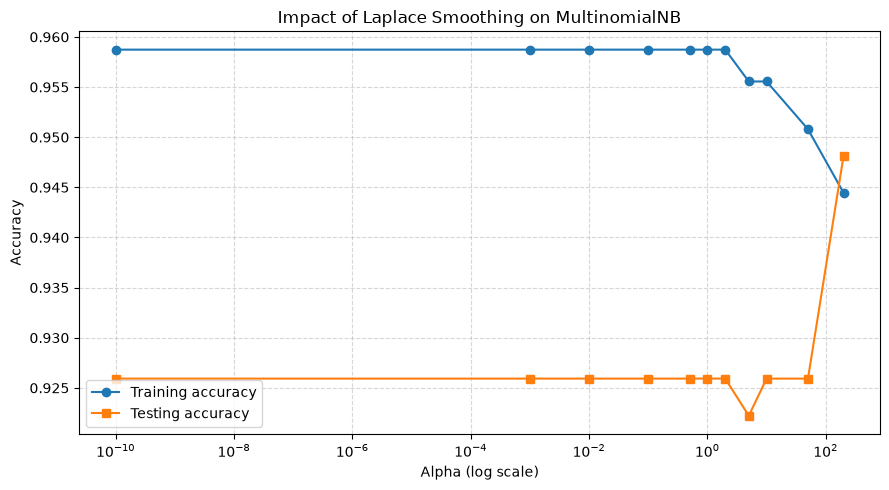

In [20]:
alphas = [1e-10, 1e-3, 0.01, 0.1, 0.5, 1, 2, 5, 10, 50, 200]
train_accs, test_accs = [], []

for a in alphas:
    m = MultinomialNB(alpha=a, force_alpha=True).fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, m.predict(X_train)))
    test_accs.append(accuracy_score(y_test, m.predict(X_test)))

display(pd.DataFrame({'alpha': alphas, 'train_acc': train_accs, 'test_acc': test_accs}))    
plt.figure(figsize=(9, 5))

plt.plot(
    alphas, train_accs,
    marker='o',
    label='Training accuracy'
)

plt.plot(
    alphas, test_accs,
    marker='s',
    label='Testing accuracy'
)

plt.xscale('log')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Accuracy')
plt.title('Impact of Laplace Smoothing on MultinomialNB')

plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#### B.1.6 - Effect of alpha
Accuracy is essentially flat for small and moderate alpha ~10^(0.5), so the model is insensitive to α in that range. When al[ha becomes very large (50, 200), the pseudo-counts swamp the real counts, all P(w | C) drift toward a uniform distribution, and the data stops mattering; the prediction is then driven by the priors alone,  That's underfitting: too much smoothing erases the information in the data.

#### B.1.7 - Reflection
* (i) With a large vocabulary and little data, many words have zero or tiny counts in at least one class. Without smoothing, each of them can zero out a class, so the estimates are fragile. Smoothing matters most exactly when counts are sparse.
* (ii) Multiplying many probabilities that are each much smaller than 1 quickly underflows to 0 in floating point. Summing logs is numerically stable, turns the product into a sum, and doesn't change which class has the maximum score because log is monotonic and consistant.

## Part 3

Exactitude Apprentissage : 0.9587
Exactitude Test          : 0.9259

 classification repport (Test) :
              precision    recall  f1-score   support

    Legitime     0.9581    0.9249    0.9412       173
        Spam     0.8738    0.9278    0.9000        97

    accuracy                         0.9259       270
   macro avg     0.9159    0.9263    0.9206       270
weighted avg     0.9278    0.9259    0.9264       270



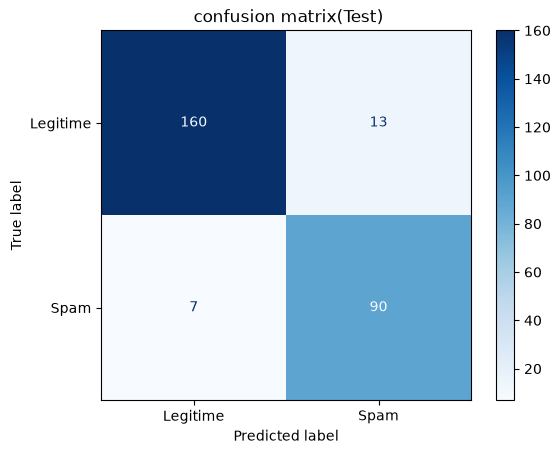

In [13]:
y_train_pred = m1.predict(X_train)
y_test_pred = m1.predict(X_test)

print(f"Train accuracy : {accuracy_score(y_train, y_train_pred):.4f}")
print(f" Test accuracy           : {accuracy_score(y_test, y_test_pred):.4f}\n")

print(" classification repport (Test) :")
print(classification_report(y_test, y_test_pred, digits=4))

cm = confusion_matrix(y_test, y_test_pred, labels=m1.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=m1.classes_)
disp.plot(cmap='Blues')
plt.title(" confusion matrix(Test)")
plt.grid(False)
plt.show()

C.1 - Performance (alpha = 1)
Train accuracy is 0.9587 and test accuracy is 0.9259. The 3-point gap is mild, not real overfitting. With 270 test emails, the standard error on the test accuracy is about 1.6 points, so the gap is within noise.
Confusion matrix (rows = true, columns = predicted): of 173 Legitimate emails, 160 are correct and 13 are flagged as Spam. Of 97 Spam emails, 90 are caught and 7 slip through. Spam precision is 0.874, Spam recall is 0.928.

C.2 - Which error is worse?
Classifying a legitimate email as Spam is the more serious error: the user may never see an important message . A spam that slips through is just an annoyance.
So the metric to watch is the precision of the Spam class (equivalently, the recall of Legitimate): of everything flagged as Spam, how much really is Spam. It's our weakest number (0.874, with 13 false positives vs 7 misses). If it needs to go up, we can raise the decision threshold on predict_proba for Spam, at the cost of lower Spam recall

,log P(w|Spam) - log P(w|Legitime)
loterie,3.340539
heritage,3.340539
gratuit,1.815843
gagner,1.628823
cliquer,1.306467
offre,1.037954
nb_liens,0.763976
urgent,0.575856
facture,0.123125
expediteur_connu,-1.254580


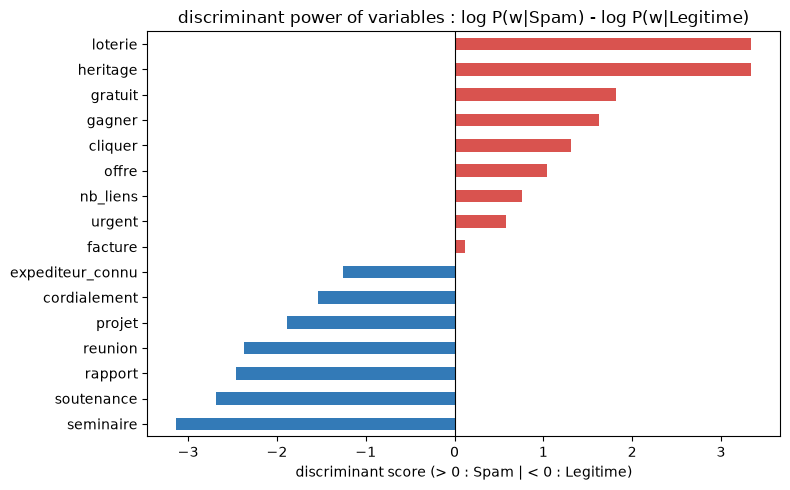

In [14]:
spam_idx = list(m1.classes_).index('Spam')
leg_idx = list(m1.classes_).index('Legitime')

discriminant = pd.Series(
    m1.feature_log_prob_[spam_idx] - m1.feature_log_prob_[leg_idx],
    index=X.columns,
    name='log P(w|Spam) - log P(w|Legitime)'
).sort_values(ascending=False)

display(discriminant.to_frame())

plt.figure(figsize=(8, 5))
colors = ['#d9534f' if v > 0 else '#337ab7' for v in discriminant.values]
discriminant.sort_values().plot(kind='barh', color=colors[::-1])
plt.axvline(0, color='black', linewidth=0.8)
plt.title("discriminant power of variables : log P(w|Spam) - log P(w|Legitime)")
plt.xlabel("discriminant score (> 0 : Spam | < 0 : Legitime)")
plt.tight_layout()
plt.show()

C.3 - Discriminant words
Strongest spam indicators: loterie and heritage (+3.34), gratuit (+1.82), gagner (+1.63), cliquer (+1.31), offre (+1.04). Strongest legitimate indicators: seminaire (-3.13), soutenance (-2.69), rapport (-2.47), reunion (-2.37), projet (-1.89), cordialement (-1.54), and a known sender (-1.25). facture is near 0 (+0.12), so it doesn't discriminate. This matches intuition.
note: loterie/heritage/seminaire/soutenance score so high mainly because they are class-exclusive, so their score depends on the smoothing constant. They're rare, so they rarely decide an email. Also, nb_liens and expediteur_connu aren't words, just extra features.

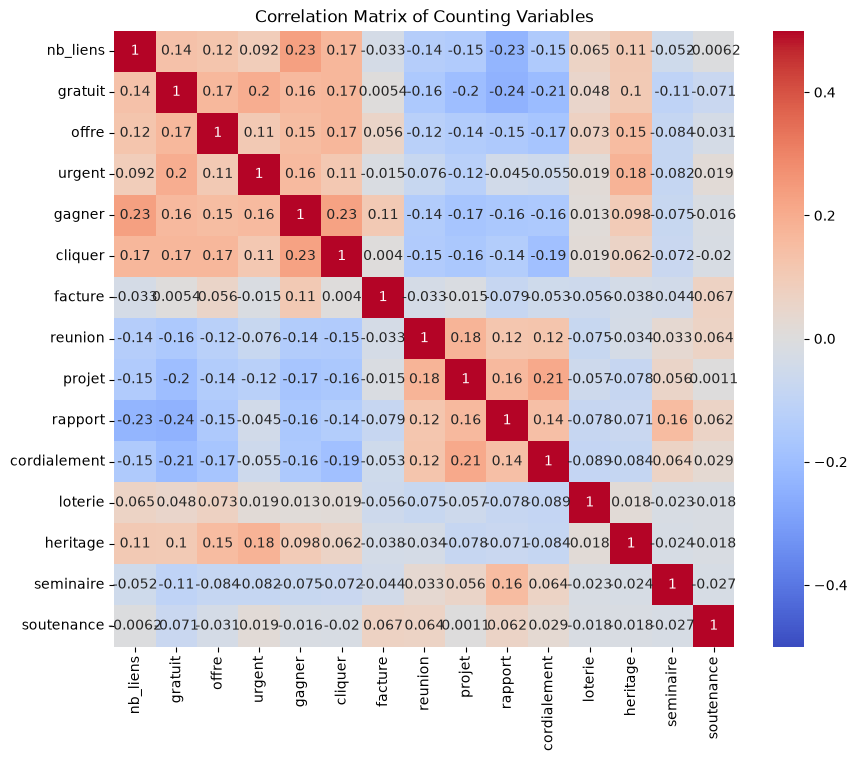

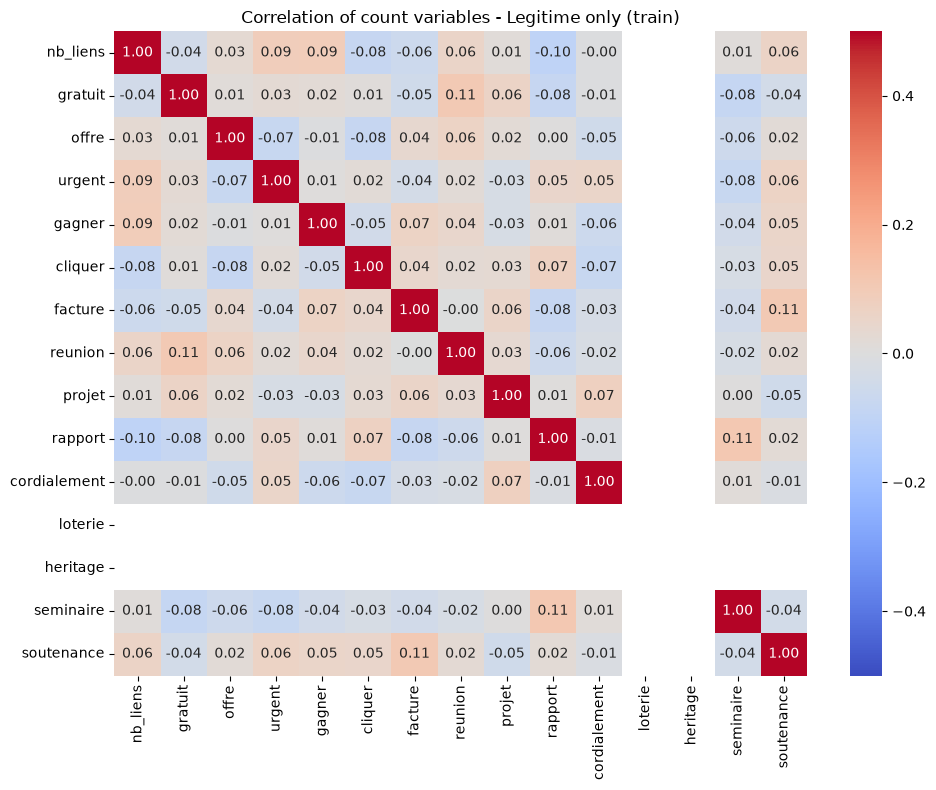

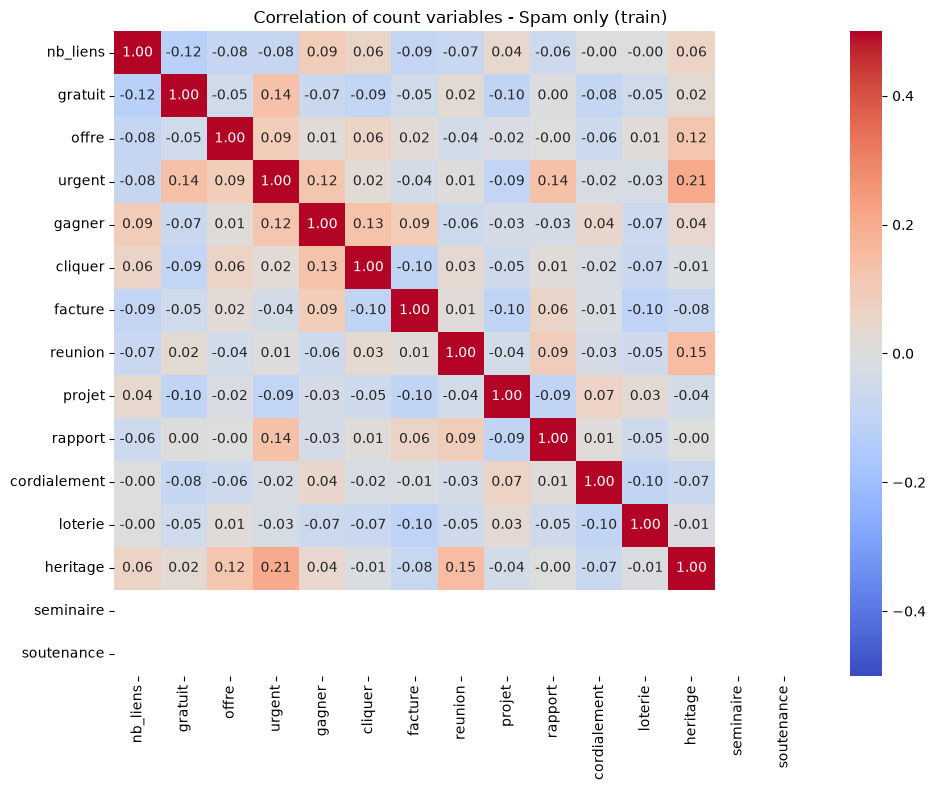

overall   : 0.09803847937993057
Legitime : nan
Spam : nan


<Figure size 640x480 with 0 Axes>

In [25]:
count_cols = [c for c in X.columns if c != 'expediteur_connu']

corr_matrix = X_train[count_cols].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-0.5,
    vmax=0.5,
    annot=True
)
plt.title("Correlation Matrix of Counting Variables")
for cls in m1.classes_:
    Xc = X_train.loc[y_train == cls, count_cols]
    plt.figure(figsize=(10, 8))
    sns.heatmap(Xc.corr(), cmap='coolwarm', center=0, vmin=-0.5, vmax=0.5, annot=True, fmt=".2f")
    plt.title(f"Correlation of count variables - {cls} only (train)")
    plt.tight_layout()
    plt.show()

def mean_abs_offdiag(c):
    return np.abs(c.values[~np.eye(len(c), dtype=bool)]).mean()

print("overall   :", mean_abs_offdiag(X_train[count_cols].corr()))
for cls in m1.classes_:
    print(cls, ":", mean_abs_offdiag(X_train.loc[y_train == cls, count_cols].corr()))

#
plt.tight_layout()
plt.show()

C.4 - Naive assumption
Over the whole training set, many count variables are correlated: spam words are positively correlated with each other, professional words too, and the two groups are negatively correlated. But this is mostly caused by the class itself (an email that is Spam tends to contain all the spam words). Inside each class, the mean absolute correlation drops from X (overall) to Y (Spam) and Z (Legitimate).
So conditional independence is roughly plausible .  expect it to hold well on this dataset because it was generated artificially, but in real emails words co-occur beyond their class ("free" and "offer").
Naive Bayes can still work well because it only needs the ranking of the classes to be right, not calibrated probabilities. Dependencies tend to inflate both classes' scores in a similar way, so the argmax rarely flips. 

In [16]:
param_grid = {'alpha': [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]}
grid = GridSearchCV(MultinomialNB(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)

print("best alpha :", grid.best_params_)
print(f"Meilleur score CV (5-fold) : {grid.best_score_:.4f}")

cv_results = pd.DataFrame({
    'alpha': grid.cv_results_['param_alpha'],
    'mean_cv_accuracy': grid.cv_results_['mean_test_score']
})
display(cv_results)

best alpha : {'alpha': 2}
Meilleur score CV (5-fold) : 0.9524


,alpha,mean_cv_accuracy
0,0.001,0.949206
1,0.010,0.949206
2,0.100,0.949206
3,0.500,0.949206
4,1.000,0.950794
5,2.000,0.952381
6,5.000,0.952381
7,10.000,0.949206


C.5 - Choosing alpha
Best alpha is 2 (CV accuracy 0.9524), but the whole grid sits in 0.9492-0.9524. That total spread is about 2 emails out of 630, and alpha = 2 vs alpha = 1 is a 1-email difference. So the choice is not meaningful: the model is insensitive to alpha on this range.
This agrees with B.1.6, where accuracy was flat for small and moderate alpha. The grid stops at 10 so it doesn't reach the underfitting regime (alpha = 50-200), though CV accuracy already dips slightly at alpha = 10. One methodological difference: GridSearchCV selects alpha using only training folds, whereas the B.1.6 curve uses test accuracy, so it shouldn't be used to pick alpha.

In [17]:
mots = [
    'gratuit', 'offre', 'urgent', 'gagner', 'cliquer',
    'facture', 'reunion', 'projet', 'rapport',
    'cordialement', 'loterie', 'heritage',
    'seminaire', 'soutenance'
]

spam_idx = list(m1.classes_).index('Spam')
leg_idx = list(m1.classes_).index('Legitime')

indices = [X.columns.get_loc(c) for c in mots]

discriminant = pd.Series(
    m1.feature_log_prob_[spam_idx, indices] -
    m1.feature_log_prob_[leg_idx, indices],
    index=mots,
    name='Discriminant score'
).sort_values(ascending=False)

display(discriminant.to_frame())

,Discriminant score
loterie,3.340539
heritage,3.340539
gratuit,1.815843
gagner,1.628823
cliquer,1.306467
offre,1.037954
urgent,0.575856
facture,0.123125
cordialement,-1.541274
projet,-1.891638


In [23]:
x_new = pd.DataFrame([dict.fromkeys(X.columns, 0)])
x_new[['gratuit', 'offre', 'urgent', 'cliquer', 'nb_liens', 'expediteur_connu']] = [3, 2, 1, 2, 4, 0]

print("manual calc of score log P(C) + sum(x_i * log P(w_i | C)) :")
for idx, cls in enumerate(m1.classes_):
    log_prior = m1.class_log_prior_[idx]
    log_likelihood = np.dot(x_new.iloc[0].values, m1.feature_log_prob_[idx])
    total_score = log_prior + log_likelihood
    print(f"  Classe {cls:8s} : log_prior = {log_prior:.6f} | somme = {log_likelihood:.6f} | Score total = {total_score:.6f}")

print("\n verefication with scikit-learn :")
print("  predict()       :", m1.predict(x_new)[0])
print("  predict_proba() :", dict(zip(m1.classes_, np.round(m1.predict_proba(x_new)[0], 6))))
print('\n')

scores = np.array([m1.class_log_prior_[i] + x_new.iloc[0].values @ m1.feature_log_prob_[i] for i in range(2)])
post = np.exp(scores - scores.max()); post /= post.sum()
print("Posterior from scores:", dict(zip(m1.classes_, post.round(8))))

manual calc of score log P(C) + sum(x_i * log P(w_i | C)) :
  Classe Legitime : log_prior = -0.444305 | somme = -36.477776 | Score total = -36.922081
  Classe Spam     : log_prior = -1.025185 | somme = -22.709646 | Score total = -23.734831

 verefication with scikit-learn :
  predict()       : Spam
  predict_proba() : {np.str_('Legitime'): np.float64(2e-06), np.str_('Spam'): np.float64(0.999998)}


Posterior from scores: {np.str_('Legitime'): np.float64(1.87e-06), np.str_('Spam'): np.float64(0.99999813)}


C.6 - Manual scoring
Score = log P(C) + Σ xᵢ log P(wᵢ | C):

Legitimate: -0.444 + (-36.478) = -36.922
Spam: -1.025 + (-22.710) = -23.735

Spam has the higher score, so the prediction is Spam, which matches predict(). Scores aren't probabilities, but their difference gives the odds: 36.922 - 23.735 = 13.19, and e^-13.19 ≈ 1.9×10^-6, which is exactly the P(Legitimate) returned by predict_proba (1.87×10^-6). The priors barely matter here: the likelihood term dominates.

Conclusion
Multinomial NB reaches ~92.6% test accuracy (~95% in CV) despite its naive independence assumption. Smoothing doesn't change average accuracy but prevents unseen words from vetoing a class (trap email), and very large alpha causes underfitting. The weakest point is Spam precision (0.874); the model is also overconfident, so its probabilities shouldn't be taken literally.